# VAE-based with PyTorch
### Example with MNIST datas (possible 1D, 2D or 3D)

## 1. Import des bibliothèques python

In [84]:
%load_ext autoreload
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
import torch.nn.functional as Funct
from torch.optim.lr_scheduler import CosineAnnealingLR, ReduceLROnPlateau

# personnal
import libraries
import libraries.data_loader as dl
from libraries.gen_masks import get_masks
from libraries.latent import get_RT_X
from libraries.display import display_group_images

import libraries.models as model
from libraries.model_parts.cnn import CNN_28x28, TCNN_28x28

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


## 2. Load MNIST and RT-MNIST

In [81]:
path = r"datas/mnist.npz"
keys = ['x_train', 'y_train', 'x_test', 'y_test']

X_train, Y_train, X_val, Y_val = dl.load_datas(path, keys)


X_train = X_train.reshape((60000, 1, 28, 28))
X_val = X_val[:].reshape((10000, 1, 28, 28))


X_train.shape, X_val.shape

((60000, 1, 28, 28), (10000, 1, 28, 28))

In [82]:
path = r"datas/rt-mnist.npz"
keys = ["masks"] # , "MUS", "STDS"
M = None
with np.load(path) as f:
    M = [f[k] for k in keys]

M = M[0]
M.shape

(60000, 28, 28)

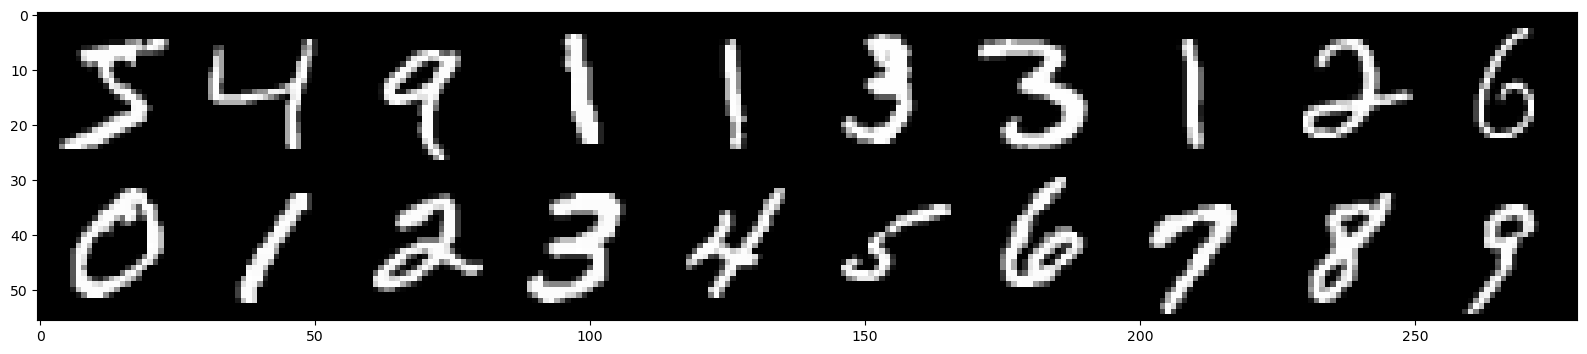

In [85]:
index = 20
display_group_images(X_train[:index], cmap = "gray")

In [86]:
X_train.max(), M.max()

(255, 255)

## 3. Model

In [87]:
%autoreload 2
modes = {
    "VAE": {
        "F": 1,
        "model" : model.VAE,
        "loss" : ["loss", "IMG", "KLD"], 
        "rep": "MNIST"
    }, 
    "VAE-RT":{
        "F": 2,
        "model" : model.VAE,
        "loss" : ["loss", "STRUCT", "DOSE", "KLD"], 
        "rep": "RT-MNIST"
    }, 
    "TCVAE":{
        "F": 1,
        "model" : model.TCVAE,
        "loss" : ["loss", "IMG", "KLD", "COV"], 
        "rep": "MNIST"
    }, 
    "TCVAE-RT": {
        "F": 2,
        "model" : model.TCVAE,
        "loss" : ["loss", "STRUCT", "DOSE", "KLD", "COV"], # TC-COV :  
        "rep": "RT-MNIST"
    },
    "DVAE": {
        "F": 1,
        "model" : model.DVAE,
        "loss" : ["loss", "IMG", "KLD", "ORT"]
    },
    "DVAE-RT": {
        "F": 2,
        "model" : model.DVAE,
        "loss" : ["loss", "STRUCT", "DOSE", "KLD", "ORT"]
    }

}


mode = "DVAE"
str_loss_colnames = modes[mode]["loss"]

In [88]:
%autoreload 2
F = modes[mode]["F"] # F : input filter
D = 50
FILTER = 25
TC = modes[mode]["loss"][-1]


torch.manual_seed(42)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
net = modes[mode]["model"](CNN_28x28, TCNN_28x28, D, F, FILTER).to(device)

In [89]:
X = X_train[:5].astype(np.float32) /255.
if F == 2 :
    X = get_RT_X(X_train[:batch], M[:batch])
X = torch.from_numpy(X)
pred = net.vae.pred(X)
# pred_1 = check_nets[1].vae.pred(X)

len(pred)

4

In [90]:
pred[-1].shape

torch.Size([5, 50])

In [91]:
alpha, beta, gamma = 0.5, 0.5, 10

losses = net(X, alpha = alpha, beta = beta, gamma = gamma)
losses[:]

(tensor(4323.7632, grad_fn=<AddBackward0>),
 2780.638671875,
 29.667892456054688,
 152.82904052734375)

In [92]:
optimizer = torch.optim.Adam(params=net.parameters(), lr=0.001, weight_decay=1e-4)
optimizer.zero_grad()
losses[0].backward()
optimizer.step()

## 4. Train

In [93]:
# Pour l'affichage et le temps d'apprentissage
from IPython.display import clear_output
import time

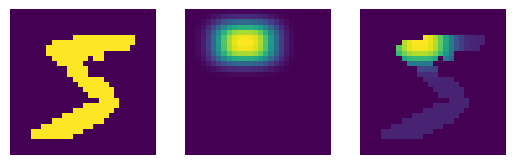

In [94]:
x = X_train[:1].copy()
mask, _, _ = get_masks(x, 3, seed = 2)
d = x[:, 0]*mask

fig, axes = plt.subplots(1, 3, frameon = False)
i = 0
axes[0].imshow(x[i, 0])
axes[1].imshow(mask[i])
axes[2].imshow(d[i])
axes[0].set_axis_off()
axes[1].set_axis_off()
axes[2].set_axis_off()
plt.savefig("img.pdf")

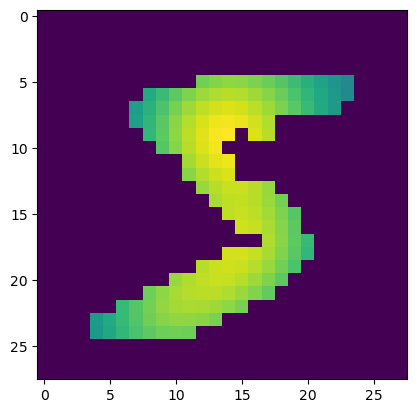

In [95]:
x = X_train[:1].copy()
D = []
for i in range(500) :
    
    mask, _, _ = get_masks(x, 3, seed = i)
    D.append(x[:, 0]*mask)
D = np.array(D)
X = x.repeat(500, axis = 0)
t = (X*D).mean(axis = (0, 1))
plt.imshow(t)

In [97]:
def train(mode, X_train, M, alpha = 0.5, beta = 0.5, gamma = 1., cur_epoch = 1, epochs = 100, batchsize = 1000) :
    str_loss_colnames = mode["loss"]
    F = mode["F"] # F : input filter
    D = 50
    FILTER = 25
    
    torch.manual_seed(42)
    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    net = mode["model"](CNN_28x28, TCNN_28x28, D, F, FILTER).to(device)
    net.vae.train()
    
    learning_rate = 1e-3
    
    torch.manual_seed(42)
    optimizer = torch.optim.Adam(params=net.parameters(), lr=learning_rate, weight_decay=1e-4)
    # cosine_scheduler = CosineAnnealingLR(optimizer, T_max = 10, eta_min = 1e-5)
    # plateau_scheduler = ReduceLROnPlateau(optimizer, factor=0.5, patience=5, cooldown=2, min_lr=1e-5)
    
    
    batch_range_train = range(0, X_train.shape[0] +1, batchsize) # 
    ratio = 100 /batchsize /np.prod(X_train.shape[1:]) # Avoir une erreur relative à la dimension des données et de la taille du batch
    
    # Passe le modèle en mode "apprentissage"
    net = net.to(device)
    net = net.train()
    
    
    print(f"{cur_epoch}/{epochs}, Entraînement du modèle")
    
    AVG_loss = []
    learning_rates = []
    begin = time.time()
    for epoch in range(cur_epoch, epochs +1):
        print(f"epoch {epoch}/{epochs}")
        avg_loss = []
        cur_lrs = []
        
        # Parcours du dataset pour une epoch
        MASKS, _, _ = get_masks(X_train[:1].copy(), 3, seed = epoch)
        # MASKS = M[:1]
        if F == 1 :
            display_epoch(net.vae, torch.from_numpy(X_train[:1].astype(np.float32)/255.), F = 1, epoch = epoch)
        if F == 2 :
            RT_X = get_RT_X(X_train[:1], MASKS.astype(np.float32))
            display_epoch(net.vae, torch.from_numpy(RT_X), epoch = epoch)
        
        for i, batch in enumerate(batch_range_train[:-1]) :
            cur_seed = epoch*len(batch_range_train) +i
            X = X_train[batch:batch_range_train[i +1]].astype(np.float32) /255.
            if F == 2 : 
                MASKS, _, _ = get_masks(X_train[batch:batch_range_train[i +1]].copy(), 3, seed = 0)
                # MASKS = M[batch:batch_range_train[i +1]]
                X = get_RT_X(X_train[batch:batch_range_train[i +1]], MASKS.astype(np.float32)) # 
            X = torch.from_numpy(X)
            X = X.to(device)
            
            # Calcul de l'erreur
            losses = None
            if epoch <= 50 :
                losses = net(X, alpha = alpha, beta = 0, gamma = gamma)
            elif (epoch > 50) and (epoch <= 100) :
                losses = net(X, alpha = alpha, beta = beta *(2*epoch/100 -1), gamma = gamma) # X, beta = 1. # 9 *epoch/epochs +1
            else :
                losses = net(X, alpha = alpha, beta = beta, gamma = gamma) 
    
            # Rétropropagation du gradient
            optimizer.zero_grad()
            losses[0].backward()
            # Descente de gradient (une itération)
            optimizer.step()
    
            loss = np.array([losses[0].item()] + list(losses[1:])) *ratio
            str_loss = [f"{s}: {np.round(l, 4)}" for s, l in zip(str_loss_colnames, loss)]
            str_loss = " ; ".join(str_loss)
            cur_lr = optimizer.param_groups[0]["lr"]
            print(f"{epoch} {i +1} " + str_loss, "- lr = ", cur_lr)
            avg_loss.append(loss)
            cur_lrs.append([cur_lr])
            
        AVG_loss.append(avg_loss)
        learning_rates.append(cur_lrs)
        
        # cosine_scheduler.step()
        # plateau_scheduler.step(loss[0])
        
        clear_output()
    end = time.time()

    return net, np.concatenate(AVG_loss), np.concatenate(learning_rates), end -begin 

In [98]:
keys = [key for key in modes.keys()] #  if "DVAE" in key
keys = ['TCVAE']

In [ ]:
%autoreload 2
alpha = 0.25
beta = 1
gamma = 1000 # 2.-beta

cur_epoch = 1
epochs, batchsize = 200, 1000
save = True
NETS, AVGS, LRS, DELAIS = [], [], [], []
for mode in list(keys)[:] :
    net, AVG, LR, delais = train(modes[mode], X_train[:], M[:], alpha, beta, gamma, cur_epoch = cur_epoch, epochs = epochs)
    NETS.append(net)
    AVGS.append(AVG)
    LRS.append(LR)
    DELAIS.append(delais)

    path = os.path.join("Results", "Results 28x28 annealing", mode)

    rep = []
    if "RT" in mode : 
        rep.append(f"alpha_{alpha}")
    
    if "VAE" in mode :
        rep.append(f"beta_{beta}")
    
    if "TC" in mode :
        rep.append(f"gamma_{gamma}")
    
    rep = "-".join(rep)

    global_path = os.path.join(path, rep)
    if not os.path.isdir(global_path) and save :
        os.mkdir(global_path)

        AVG = pd.DataFrame(AVG, columns = modes[mode]["loss"])
        AVG_loss_path = os.path.join(global_path, r"loss.csv")
        AVG.to_csv(AVG_loss_path, index = False, sep = ";", encoding = "utf-8")

        LR = pd.DataFrame(LR, columns = ["learning_rate"])
        LR_path = os.path.join(global_path, r"learning_rate.csv")
        LR.to_csv(LR_path, index = False, sep = ";", encoding = "utf-8")
    
        model_path = os.path.join(global_path, r"model.pt")
        torch.save(net, model_path)
        print("Done !")

In [100]:
modes[mode]

{'F': 1,
 'model': libraries.models.TCVAE,
 'loss': ['loss', 'IMG', 'KLD', 'COV'],
 'rep': 'MNIST'}

In [41]:
global_path

'Results\\Results 28x28 annealing\\TCVAE\\beta_0.5-gamma_100'

## 5. Vérification

In [42]:
check_net = torch.load(model_path, weights_only=False)

In [46]:
X.shape

torch.Size([50, 2, 28, 28])

In [47]:
batch = 50
F = 1
X = X_train[:batch].astype(np.float32) /255.
if F == 2 :
    X = get_RT_X(X_train[:batch], M[:batch])
X = torch.from_numpy(X)
pred = check_net.vae.pred(X)
len(pred)

4

In [48]:
hat_X, MU, LOGVAR, Z = pred

TCVAE


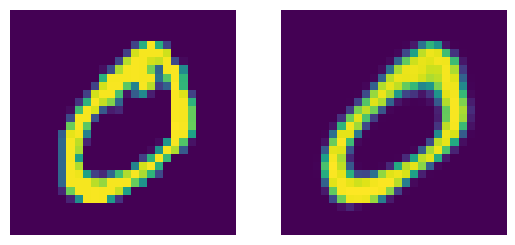

In [49]:
idx = 1
display_epoch(net.vae, X[idx:idx +1], F)

In [127]:
MU = MU.detach().numpy()
LOGVAR = LOGVAR.detach().numpy()

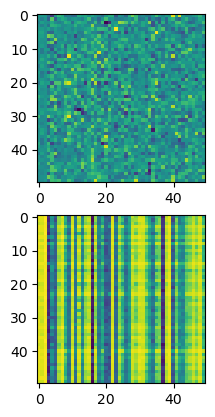

In [128]:
fig, ax = plt.subplots(2, 1)

idx = 2

for i in range(2) :
    ax[0].imshow(MU)
    ax[1].imshow(LOGVAR)

In [129]:
C, S = torch.split(Z, D//2, 1)
C = C.detach().numpy()
S = S.detach().numpy()

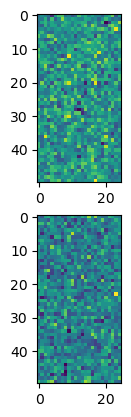

In [130]:
fig, ax = plt.subplots(2, 1)

idx = 2

for i in range(2) :
    ax[0].imshow(C)
    ax[1].imshow(S)

In [53]:
AVG_loss_path

'Results\\Results 28x28 annealing\\TCVAE\\beta_0.5-gamma_100\\loss.csv'

In [72]:
AVG_loss_path = r'Results\\Results 28x28 annealing\\TCVAE\\beta_0.5-gamma_100\\loss.csv'
loaded_AVG_loss = pd.read_csv(AVG_loss_path, index_col = None, sep = ";", encoding = "utf-8")
AVG_loss_path_2 = r'Results\\Results 28x28 annealing\\TCVAE\\beta_0.5-gamma_10\\loss.csv'
loaded_AVG_loss_2 = pd.read_csv(AVG_loss_path_2, index_col = None, sep = ";", encoding = "utf-8")

In [73]:
loaded_AVG_loss.iloc[-4:]

,loss,IMG,KLD,COV
11996,14.246078,7.909882,11.160308,0.007560
11997,14.562122,8.161796,11.298012,0.007513
11998,14.587176,8.093300,11.346355,0.008207
11999,14.531995,8.138985,11.443648,0.006712


In [74]:
loaded_AVG_loss_2.iloc[-4:]

,loss,IMG,KLD,COV
11996,12.462006,7.795335,7.985507,0.067392
11997,12.632143,7.977622,7.825639,0.074170
11998,12.732000,7.995556,7.934065,0.076941
11999,12.760616,8.023155,8.235376,0.061977


In [63]:
AVG_loss_path

'Results\\Results 28x28 annealing\\TCVAE\\beta_0.5-gamma_100\\loss.csv'

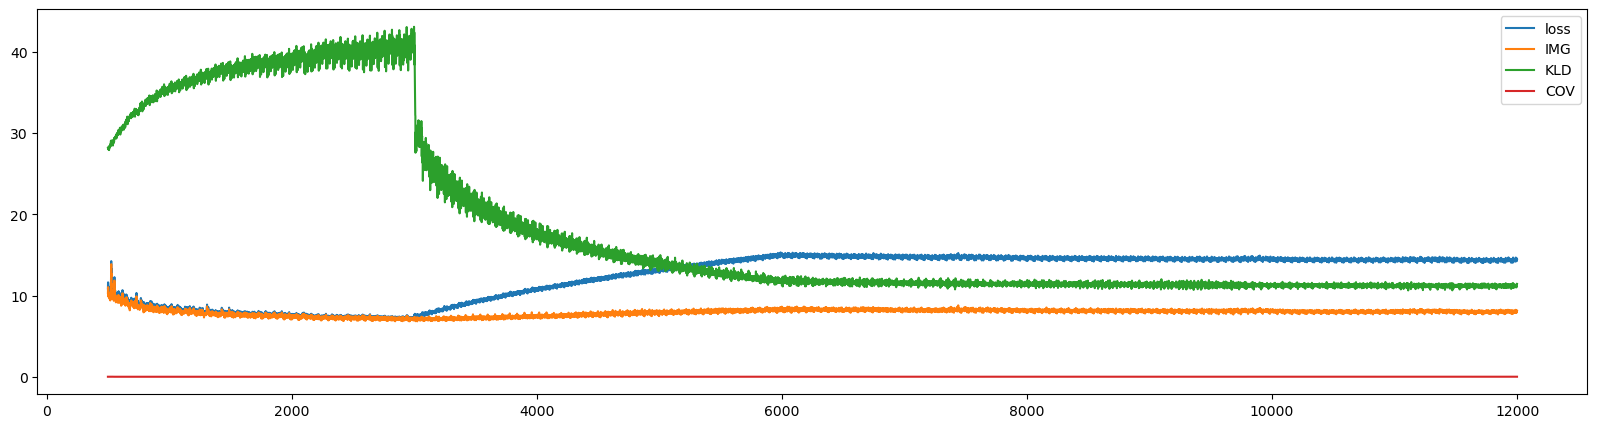

In [66]:
loaded_AVG_loss = pd.read_csv(AVG_loss_path, index_col = None, sep = ";", encoding = "utf-8")
colnames = loaded_AVG_loss.columns
plt.figure(figsize = (20, 5))
plt.plot(loaded_AVG_loss.iloc[500:])
plt.legend(colnames)

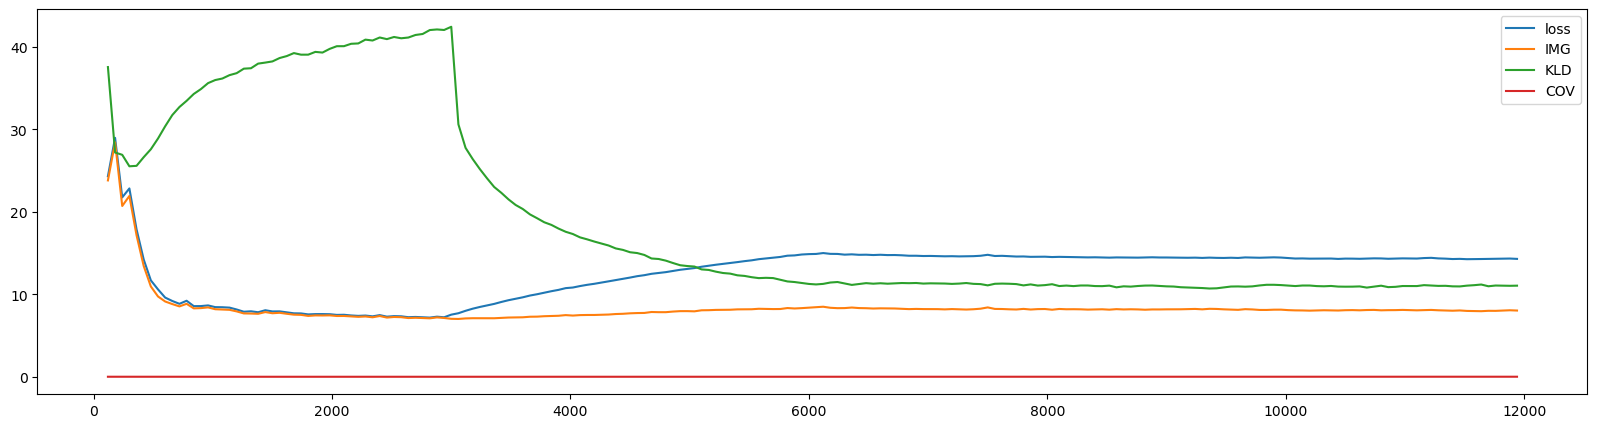

In [52]:
loaded_AVG_loss = pd.read_csv(AVG_loss_path, index_col = None, sep = ";", encoding = "utf-8")
colnames = loaded_AVG_loss.columns
plt.figure(figsize = (20, 5))
plt.plot(loaded_AVG_loss.iloc[np.arange(120, len(loaded_AVG_loss), 60)])
plt.legend(colnames)

# 6. Voir la forme de l'espace latent

In [132]:
check_net = torch.load(model_path, weights_only=False)

In [135]:
batch_range_train = range(0, X_train.shape[0] +1, batchsize)

MU = []
LOGVAR = []

for i, batch in enumerate(batch_range_train[:-1]) :
    X = get_RT_X(X_train[batch:batch_range_train[i +1]], M[batch:batch_range_train[i +1]])
    X = torch.from_numpy(X)
    
    Z_MU, Z_LOGVAR = check_net.vae.Encoder(X)
    MU.append(Z_MU.detach().numpy())
    LOGVAR.append(Z_LOGVAR.exp().detach().numpy())

In [136]:
MU = np.concatenate(MU)
VAR = np.concatenate(LOGVAR)

In [137]:
VAR_MEAN = np.var(MU, axis = 0)
MEAN_VAR = np.mean(VAR, axis = 0)
VAR_MEAN.shape, MEAN_VAR.shape

((50,), (50,))

In [138]:
import pandas as pd

Asquare = pd.DataFrame(VAR_MEAN/(VAR_MEAN+MEAN_VAR))
Asquare = Asquare.sort_values(by = 0, ascending=  False).reset_index()
Asquare

,index,0
0,16,0.995309
1,3,0.994859
2,37,0.994353
3,20,0.987962
4,5,0.985548
5,21,0.982848
6,40,0.981914
7,23,0.978381
8,9,0.973499
9,11,0.971854


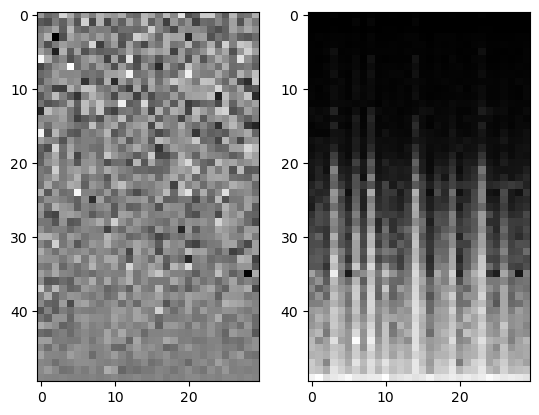

In [139]:
fig, ax = plt.subplots(1, 2)

idx = 2

for i in range(2) :
    ax[0].imshow(MU[:30, Asquare["index"]].T, cmap = "gray")
    ax[1].imshow(VAR[:30, Asquare["index"]].T, cmap = "gray")

In [101]:
50 *50/28**2

3.188775510204082